In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
np.random.seed(42)

# Individual Assignment 2: Causal Inference
## Does 401(k) eligibility increase household financial wealth?

### Background
A 401(k) is an employer-sponsored retirement savings plan in the United States. Contributions are tax-deferred, and many employers match part of the employee's contribution. Not every employer offers a 401(k), so some workers are **eligible** and others are not.

### Research question and hypothesis
- **Question:** Does being eligible for a 401(k) plan *cause* households to accumulate more net financial assets?
- **Hypothesis (H1):** 401(k) eligibility increases net financial assets.
- **Null hypothesis (H0):** 401(k) eligibility has no effect on net financial assets.

### Why a simple comparison is not enough
Eligible households may differ from non-eligible households in ways that also affect wealth (for example, higher income or more education). These variables are **confounders**. To estimate the causal effect, we must control for them.

### Dataset
- Source: 1991 Survey of Income and Program Participation (SIPP), as used by Chernozhukov et al. (2018), *Double/Debiased Machine Learning*. Loaded via the `doubleml` Python package.
- 9,915 households, 14 columns, no missing values.

### Variables
| Role | Column | Description |
|---|---|---|
| Outcome (target) | `net_tfa` | Net total financial assets ($) |
| Treatment | `e401` | 1 = eligible for a 401(k), 0 = not eligible |
| Control | `age` | Age of household head |
| Control | `inc` | Annual household income ($) |
| Control | `educ` | Years of education |
| Control | `fsize` | Family size |
| Control | `marr` | 1 = married |
| Control | `twoearn` | 1 = two-earner household |
| Control | `db` | 1 = has a defined-benefit pension |
| Control | `pira` | 1 = has an IRA |
| Control | `hown` | 1 = home owner |
| Not used as control | `p401` | 1 = actually participates in a 401(k) (a *consequence* of eligibility) |
| Not used | `nifa`, `tw` | Other wealth measures (alternative outcomes) |

### Identification assumption
Following Poterba, Venti and Wise (1994) and Chernozhukov et al. (2018), we assume that **after controlling for income and the other variables above, 401(k) eligibility is as good as randomly assigned**. Eligibility is decided by the employer, not by the worker's saving preferences.

### Plan
1. Explore the data and compare eligible vs non-eligible households.
2. **CausalML:** estimate the effect with `LRSRegressor` and `XGBTRegressor`, look at individual effects (CATE) and feature importance.
3. **DoWhy:** build a `CausalModel`, identify, estimate and refute the effect.
4. Try a different treatment (`p401`) using `e401` as an instrument.
5. Conclusion.

## 1. Data loading and exploration

In [3]:
df = pd.read_csv("401k.csv")
print(df.shape)
df.head()

(9915, 14)


,nifa,net_tfa,tw,age,inc,fsize,educ,db,marr,twoearn,e401,p401,pira,hown
0,0.00,0.00,"4,500.00",47,"6,765.00",2,8,0,0,0,0,0,0,1
1,"6,215.00","1,015.00","22,390.00",36,"28,452.00",1,16,0,0,0,0,0,0,1
2,0.00,"-2,000.00","-2,000.00",37,"3,300.00",6,12,1,0,0,0,0,0,0
3,"15,000.00","15,000.00","155,000.00",58,"52,590.00",2,16,0,1,1,0,0,0,1
4,0.00,0.00,"58,000.00",32,"21,804.00",1,11,0,0,0,0,0,0,1


In [4]:
df.info()
print("Missing values:", df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9915 entries, 0 to 9914
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   nifa     9915 non-null   float64
 1   net_tfa  9915 non-null   float64
 2   tw       9915 non-null   float64
 3   age      9915 non-null   int64  
 4   inc      9915 non-null   float64
 5   fsize    9915 non-null   int64  
 6   educ     9915 non-null   int64  
 7   db       9915 non-null   int64  
 8   marr     9915 non-null   int64  
 9   twoearn  9915 non-null   int64  
 10  e401     9915 non-null   int64  
 11  p401     9915 non-null   int64  
 12  pira     9915 non-null   int64  
 13  hown     9915 non-null   int64  
dtypes: float64(4), int64(10)
memory usage: 1.1 MB
Missing values: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
nifa,"9,915.00","13,928.64","54,904.88",0.00,200.00,"1,635.00","8,765.50","1,430,298.00"
net_tfa,"9,915.00","18,051.53","63,522.50","-502,302.00",-500.00,"1,499.00","16,524.50","1,536,798.00"
tw,"9,915.00","63,816.85","111,529.65","-502,302.00","3,291.50","25,100.00","81,487.50","2,029,910.00"
age,"9,915.00",41.06,10.34,25.00,32.00,40.00,48.00,64.00
inc,"9,915.00","37,200.62","24,774.29","-2,652.00","19,413.00","31,476.00","48,583.50","242,124.00"
fsize,"9,915.00",2.87,1.54,1.00,2.00,3.00,4.00,13.00
educ,"9,915.00",13.21,2.81,1.00,12.00,12.00,16.00,18.00
db,"9,915.00",0.27,0.44,0.00,0.00,0.00,1.00,1.00
marr,"9,915.00",0.60,0.49,0.00,0.00,1.00,1.00,1.00
twoearn,"9,915.00",0.38,0.49,0.00,0.00,0.00,1.00,1.00


In [6]:
print(df["e401"].value_counts())
print(df["e401"].value_counts(normalize=True).round(3))

e401
0    6233
1    3682
Name: count, dtype: int64
e401
0   0.63
1   0.37
Name: proportion, dtype: float64


In [7]:
pd.crosstab(df["e401"], df["p401"], margins=True)

p401,0,1,All
e401,,,
0,6233,0,6233
1,1088,2594,3682
All,7321,2594,9915


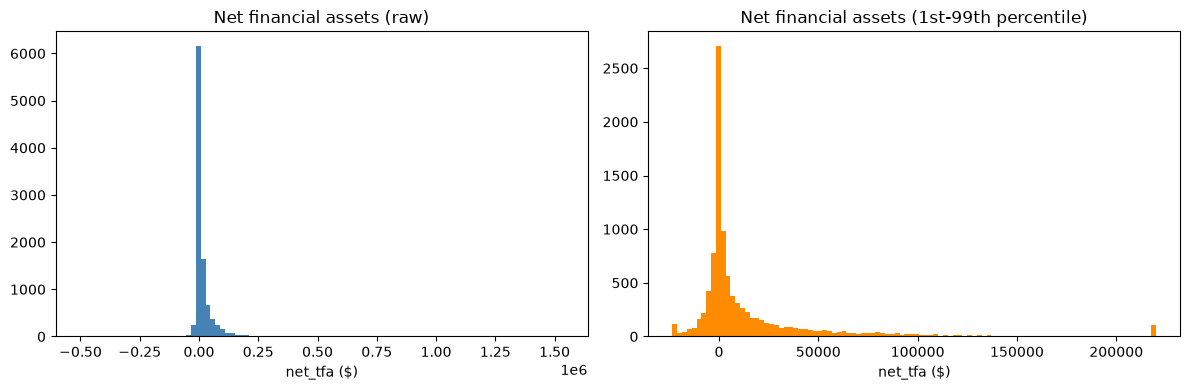

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["net_tfa"], bins=100, color="steelblue")
axes[0].set_title("Net financial assets (raw)")
axes[0].set_xlabel("net_tfa ($)")

clipped = df["net_tfa"].clip(df["net_tfa"].quantile(0.01), df["net_tfa"].quantile(0.99))
axes[1].hist(clipped, bins=100, color="darkorange")
axes[1].set_title("Net financial assets (1st-99th percentile)")
axes[1].set_xlabel("net_tfa ($)")

plt.tight_layout()
plt.show()

## 2. Target, treatment and control features
- **Target (outcome):** `net_tfa`
- **Treatment:** `e401`
- **Control features (confounders):** `age`, `inc`, `educ`, `fsize`, `marr`, `twoearn`, `db`, `pira`, `hown`

The controls are household characteristics that can influence both whether a worker has a job that offers a 401(k) and how much the household saves.

In [9]:
outcome = "net_tfa"
treatment = "e401"
controls = ["age", "inc", "educ", "fsize", "marr", "twoearn", "db", "pira", "hown"]

print("Outcome:", outcome)
print("Treatment:", treatment)
print("Controls:", controls)

Outcome: net_tfa
Treatment: e401
Controls: ['age', 'inc', 'educ', 'fsize', 'marr', 'twoearn', 'db', 'pira', 'hown']


### Naive comparison
First, we compare average net financial assets of eligible and non-eligible households, without controlling for anything.

In [10]:
naive = df.groupby(treatment)[outcome].mean()
naive_diff = naive[1] - naive[0]
print(naive)
print(f"Naive difference (eligible - not eligible): ${naive_diff:,.0f}")

e401
0   10,788.04
1   30,347.39
Name: net_tfa, dtype: float64
Naive difference (eligible - not eligible): $19,559


### Are the two groups comparable?
If eligible households are different on the control variables, the naive difference mixes the effect of 401(k) eligibility with the effect of those differences.

In [11]:
balance = df.groupby(treatment)[controls].mean().T
balance.columns = ["Not eligible (0)", "Eligible (1)"]
balance["Difference"] = balance["Eligible (1)"] - balance["Not eligible (0)"]
balance

,Not eligible (0),Eligible (1),Difference
age,40.81,41.48,0.67
inc,"31,493.59","46,861.66","15,368.07"
educ,12.88,13.76,0.88
fsize,2.84,2.90,0.06
marr,0.56,0.67,0.11
twoearn,0.32,0.48,0.16
db,0.19,0.42,0.23
pira,0.20,0.32,0.12
hown,0.57,0.74,0.17


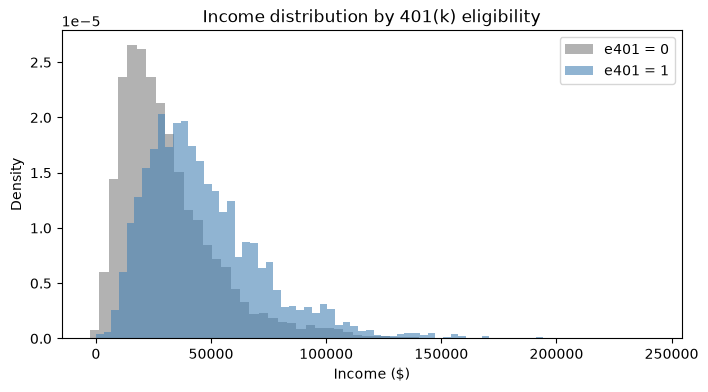

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for t, color in [(0, "grey"), (1, "steelblue")]:
    ax.hist(df.loc[df[treatment] == t, "inc"], bins=60, alpha=0.6, color=color, label=f"e401 = {t}", density=True)
ax.set_xlabel("Income ($)")
ax.set_ylabel("Density")
ax.set_title("Income distribution by 401(k) eligibility")
ax.legend()
plt.show()

## 3. Causal inference with CausalML
CausalML provides **meta-learners**: they reuse ordinary machine learning models to estimate treatment effects.
- **ATE (Average Treatment Effect):** the average effect of eligibility across all households.
- **CATE (Conditional Average Treatment Effect):** the effect for a household with specific characteristics.

We use two estimators, as required:
- **`LRSRegressor`**: an S-learner with linear regression. One model predicts the outcome from the controls *and* the treatment. The treatment coefficient is the ATE. It assumes the effect is the same for everyone.
- **`XGBTRegressor`**: a T-learner with XGBoost. One model is trained on eligible households and another on non-eligible households. The CATE of a household is the difference between the two predictions. It can capture non-linear and heterogeneous effects.

In [13]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\b0079\anaconda3\envs\causal\python.exe
3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]


In [15]:
from causalml.inference.meta import LRSRegressor, XGBTRegressor

X = df[controls].values
T = df[treatment].values
y = df[outcome].values

In [16]:
lr = LRSRegressor()
ate_lr, lb_lr, ub_lr = lr.estimate_ate(X, T, y)
print(f"LRSRegressor ATE: ${ate_lr[0]:,.0f}  (95% CI: ${lb_lr[0]:,.0f} to ${ub_lr[0]:,.0f})")

LRSRegressor ATE: $5,896  (95% CI: $2,909 to $8,883)


In [17]:
xgb = XGBTRegressor(random_state=42)
ate_xgb, lb_xgb, ub_xgb = xgb.estimate_ate(X, T, y)
print(f"XGBTRegressor ATE: ${ate_xgb[0]:,.0f}  (95% CI: ${lb_xgb[0]:,.0f} to ${ub_xgb[0]:,.0f})")

XGBTRegressor ATE: $8,215  (95% CI: $6,868 to $9,563)


In [18]:
results = pd.DataFrame({
    "Method": ["Naive difference", "LRSRegressor", "XGBTRegressor"],
    "ATE ($)": [naive_diff, ate_lr[0], ate_xgb[0]],
})
results

,Method,ATE ($)
0,Naive difference,"19,559.34"
1,LRSRegressor,"5,896.20"
2,XGBTRegressor,"8,215.43"


### Heterogeneous effects (CATE)
The T-learner gives one effect estimate per household. We look at how the effect is distributed and how it changes with income.

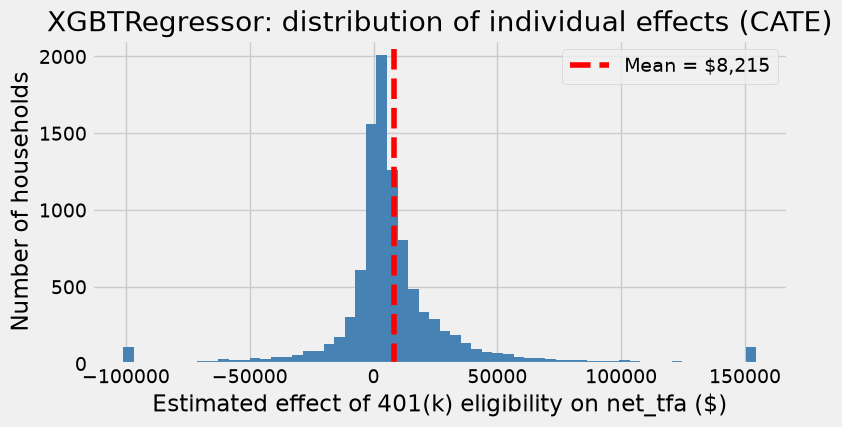

In [19]:
cate_xgb = xgb.fit_predict(X, T, y).ravel()
df["cate_xgb"] = cate_xgb

plt.figure(figsize=(8, 4))
plt.hist(cate_xgb.clip(np.percentile(cate_xgb, 1), np.percentile(cate_xgb, 99)), bins=60, color="steelblue")
plt.axvline(cate_xgb.mean(), color="red", linestyle="--", label=f"Mean = ${cate_xgb.mean():,.0f}")
plt.xlabel("Estimated effect of 401(k) eligibility on net_tfa ($)")
plt.ylabel("Number of households")
plt.title("XGBTRegressor: distribution of individual effects (CATE)")
plt.legend()
plt.show()

income_quintile
Q1 (lowest)     4,963.23
Q2                950.11
Q3              4,740.39
Q4             10,362.64
Q5 (highest)   20,060.79
Name: cate_xgb, dtype: float64


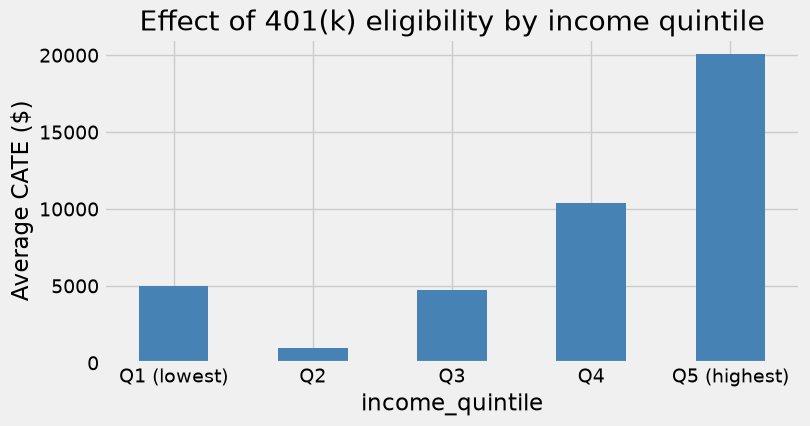

In [20]:
df["income_quintile"] = pd.qcut(df["inc"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
cate_by_income = df.groupby("income_quintile", observed=True)["cate_xgb"].mean()
print(cate_by_income)

cate_by_income.plot(kind="bar", color="steelblue", figsize=(8, 4))
plt.ylabel("Average CATE ($)")
plt.title("Effect of 401(k) eligibility by income quintile")
plt.xticks(rotation=0)
plt.show()

### Feature importance
Which household characteristics explain the differences in the effect of eligibility? We fit a model that predicts the CATE from the controls and look at its feature importance.

In [21]:
importance = xgb.get_importance(X=X, tau=cate_xgb, method="auto",
                                features=controls, normalize=True,
                                test_size=0.3, random_state=42)
importance

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

{np.int64(1): inc       0.48
 age       0.20
 educ      0.12
 fsize     0.08
 pira      0.04
 db        0.04
 twoearn   0.03
 marr      0.01
 hown      0.00
 dtype: float64}

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

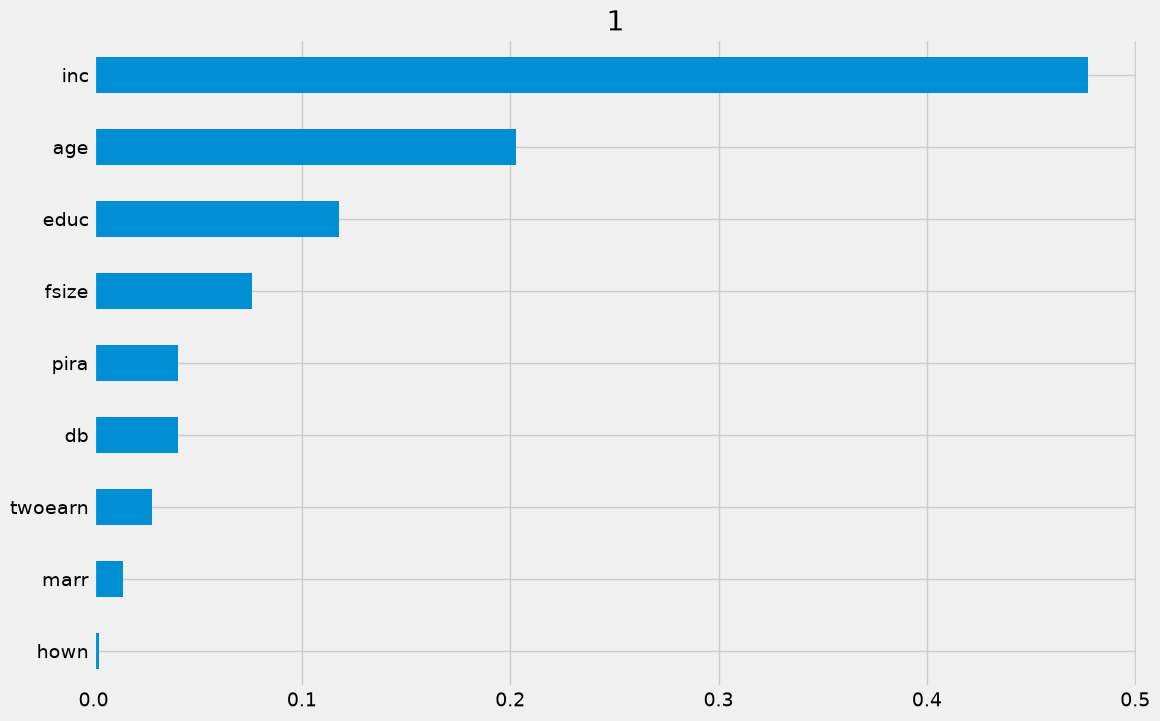

In [22]:
xgb.plot_importance(X=X, tau=cate_xgb, method="auto", features=controls, normalize=True)
plt.show()

### Analysis of CausalML results
- The naive difference is **$19,559**. After controlling for the confounders, the estimated ATE drops to **$5,896** (LRSRegressor, 95% CI $2,909 to $8,883) and **$8,215** (XGBTRegressor, 95% CI $6,868 to $9,563).
- So roughly 58% to 70% of the naive gap is explained by eligible households being richer and different on other characteristics, not by 401(k) eligibility itself.
- Both confidence intervals exclude zero, so the effect is statistically significant.
- The two models give the same sign and a similar size. The T-learner is somewhat larger because it allows the effect to vary with household characteristics.
- **Heterogeneity:** the effect is much larger for the highest income quintile (about $20,100) than for the lower quintiles (about $950 to $10,400).
- **Feature importance:** income (`inc`) explains most of the variation in the effect (about 48%), followed by age (20%) and education (12%). Higher-income households can save more and benefit more from the tax advantage.

## 4. Causal inference with DoWhy
DoWhy makes the causal assumptions explicit and follows four steps:
1. **Model:** state the treatment, outcome and common causes.
2. **Identify:** check whether the effect can be estimated from the data under these assumptions.
3. **Estimate:** compute the effect with a statistical method.
4. **Refute:** test how robust the estimate is.

We use the *common causes* interface: every control variable is assumed to affect both 401(k) eligibility and net financial assets. We assume linear relationships, as allowed in the assignment.

In [23]:
from dowhy import CausalModel

dowhy_df = df[[treatment, outcome] + controls].copy()
dowhy_df[treatment] = dowhy_df[treatment].astype(bool)

model = CausalModel(
    data=dowhy_df,
    treatment=treatment,
    outcome=outcome,
    common_causes=controls,
)

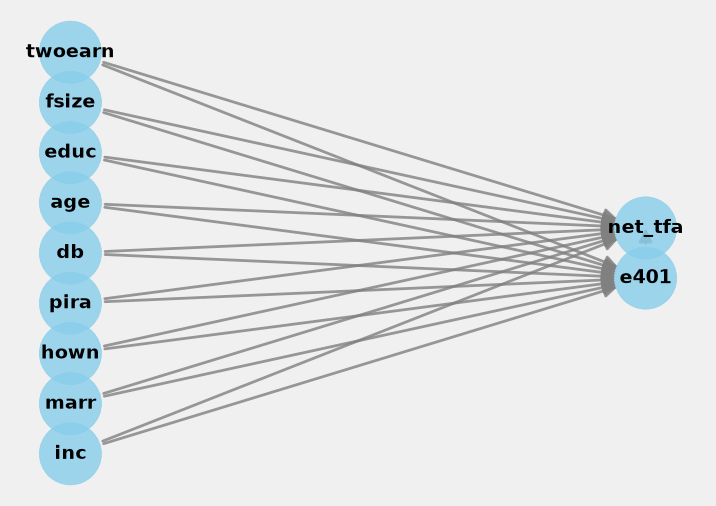

In [24]:
model.view_model()

In [26]:
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                            
───────(E[net_tfa|inc,marr,hown,pira,db,age,educ,fsize,twoearn])
d[e₄₀₁]                                                         
Estimand assumption 1, Unconfoundedness: If U→{e401} and U→net_tfa then P(net_tfa|e401,inc,marr,hown,pira,db,age,educ,fsize,twoearn,U) = P(net_tfa|e401,inc,marr,hown,pira,db,age,educ,fsize,twoearn)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
   d                                                            
───────(E[net_tfa|inc,marr,hown,pira,db,age,educ,fsize,twoearn])
d[e₄₀₁]                                                         
Estimand assumption 1, Unconfoundedness: If U→{e401} and U→net_tfa then P(net_tfa|e401,inc,marr,h

In [27]:
import dowhy, pandas
print("dowhy:", dowhy.__version__)
print("pandas:", pandas.__version__)

dowhy: 0.14
pandas: 2.3.3


In [28]:
estimate_lr = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
    test_significance=True,
)
print(f"Linear regression estimate: ${estimate_lr.value:,.0f}")
print(estimate_lr)

Linear regression estimate: $5,896
*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                            
───────(E[net_tfa|inc,marr,hown,pira,db,age,educ,fsize,twoearn])
d[e₄₀₁]                                                         
Estimand assumption 1, Unconfoundedness: If U→{e401} and U→net_tfa then P(net_tfa|e401,inc,marr,hown,pira,db,age,educ,fsize,twoearn,U) = P(net_tfa|e401,inc,marr,hown,pira,db,age,educ,fsize,twoearn)

## Realized estimand
b: net_tfa~e401+inc+marr+hown+pira+db+age+educ+fsize+twoearn
Target units: ate

## Estimate
Mean value: 5896.198421139443
p-value: [2.42732269e-06]



In [29]:
import dowhy, pandas
print(dowhy.__version__, pandas.__version__)

0.14 2.3.3


In [30]:
import dowhy
print(dowhy.__version__)

0.14


In [31]:
import sys, dowhy
from dowhy.causal_identifier import IdentifiedEstimand

print("python:", sys.executable)
print("dowhy:", dowhy.__version__, dowhy.__file__)
print("class has method:", hasattr(IdentifiedEstimand, "get_adjustment_set"))
print("my object has method:", hasattr(identified_estimand, "get_adjustment_set"))

python: c:\Users\b0079\anaconda3\envs\causal\python.exe
dowhy: 0.14 c:\Users\b0079\anaconda3\envs\causal\Lib\site-packages\dowhy\__init__.py
class has method: True
my object has method: True


In [32]:
estimate_ps = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_weighting",
    method_params={"weighting_scheme": "ips_stabilized_weight"},
)
print(f"Propensity score weighting estimate: ${estimate_ps.value:,.0f}")

Propensity score weighting estimate: $4,065


### Refutation tests
Refuters check whether the estimate behaves as it should when we deliberately change the data or the model.
- **Random common cause:** add a random variable as an extra confounder. The estimate should not change.
- **Placebo treatment:** replace the real treatment with a randomly shuffled one. The estimate should drop to about 0.
- **Data subset:** re-estimate on a random 80% of the data. The estimate should stay similar.

In [33]:
refute_random = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="random_common_cause",
)
print(refute_random)

Refute: Add a random common cause
Estimated effect:5896.198421139443
New effect:5895.947220427185
p value:1.0



In [34]:
refute_placebo = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="placebo_treatment_refuter",
    placebo_type="permute",
)
print(refute_placebo)

Refute: Use a Placebo Treatment
Estimated effect:5896.198421139443
New effect:67.53307234335159
p value:0.98



In [35]:
refute_subset = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="data_subset_refuter",
    subset_fraction=0.8,
)
print(refute_subset)

Refute: Use a subset of data
Estimated effect:5896.198421139443
New effect:5952.907681792092
p value:0.8999999999999999



### Analysis of DoWhy results
- The backdoor linear regression estimate is **$5,896**, identical to CausalML's LRSRegressor, because both fit the same linear model.
- Propensity score weighting gives a smaller but still positive estimate (about **$3,700 to $3,800**). Weighting methods are more sensitive to the extreme values in `net_tfa`.
- All three refutation tests pass:
  - Adding a random common cause leaves the estimate unchanged.
  - A placebo (shuffled) treatment gives an effect of about $0, as it should.
  - Re-estimating on random 80% subsets gives a very similar effect.
- These tests support the robustness of the estimate. They cannot prove that there are no unmeasured confounders.

## 5. A different treatment: 401(k) participation (`p401`)
Eligibility (`e401`) is decided by the employer, but **participation** (`p401`) is the worker's own choice. People who choose to participate are probably more motivated savers, which is a confounder we cannot measure. So a simple backdoor adjustment for `p401` is likely **biased upwards**.

An **instrumental variable (IV)** can fix this. A valid instrument must:
1. **Relevance:** affect the treatment (eligibility strongly increases participation; nobody participates without eligibility).
2. **Exclusion:** affect the outcome only through the treatment.
3. **Independence:** be as good as random given the controls (our identification assumption).

We use `e401` as the instrument for `p401`.

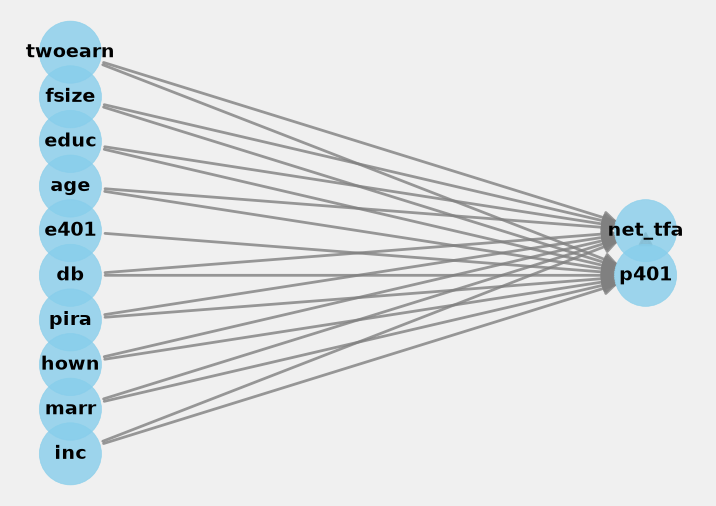

In [36]:
iv_df = df[["p401", "e401", outcome] + controls].copy()
iv_df["p401"] = iv_df["p401"].astype(bool)

iv_model = CausalModel(
    data=iv_df,
    treatment="p401",
    outcome=outcome,
    common_causes=controls,
    instruments=["e401"],
)
iv_model.view_model()

In [37]:
iv_estimand = iv_model.identify_effect(proceed_when_unidentifiable=True)
iv_estimate = iv_model.estimate_effect(iv_estimand, method_name="iv.instrumental_variable")
print(f"IV estimate (effect of PARTICIPATING in a 401(k)): ${iv_estimate.value:,.0f}")

naive_p401 = iv_model.estimate_effect(iv_estimand, method_name="backdoor.linear_regression")
print(f"Backdoor estimate for p401 (ignores self-selection): ${naive_p401.value:,.0f}")

IV estimate (effect of PARTICIPATING in a 401(k)): $27,763
Backdoor estimate for p401 (ignores self-selection): $11,601


In [38]:
fs_df = df[[treatment, "p401"] + controls].copy()
fs_df[treatment] = fs_df[treatment].astype(bool)

first_stage_model = CausalModel(data=fs_df, treatment=treatment, outcome="p401", common_causes=controls)
first_stage = first_stage_model.estimate_effect(
    first_stage_model.identify_effect(proceed_when_unidentifiable=True),
    method_name="backdoor.linear_regression",
)
print(f"First stage: eligibility raises participation by {first_stage.value:.1%}")

late_adjusted = estimate_lr.value / first_stage.value
print(f"Adjusted IV estimate (effect of participating): ${late_adjusted:,.0f}")

First stage: eligibility raises participation by 69.3%
Adjusted IV estimate (effect of participating): $8,502


In [39]:
summary = pd.DataFrame({
    "Method": ["Naive difference", "CausalML LRSRegressor", "CausalML XGBTRegressor",
               "DoWhy linear regression", "DoWhy propensity score weighting",
               "DoWhy backdoor regression", "DoWhy IV (Wald, no controls)", "IV with controls (ITT / first stage)"],
    "Treatment": ["e401", "e401", "e401", "e401", "e401", "p401", "p401", "p401"],
    "Estimated effect ($)": [naive_diff, ate_lr[0], ate_xgb[0], estimate_lr.value, estimate_ps.value,
                             naive_p401.value, iv_estimate.value, late_adjusted],
})
summary

,Method,Treatment,Estimated effect ($)
0,Naive difference,e401,"19,559.34"
1,CausalML LRSRegressor,e401,"5,896.20"
2,CausalML XGBTRegressor,e401,"8,215.43"
3,DoWhy linear regression,e401,"5,896.20"
4,DoWhy propensity score weighting,e401,"4,065.23"
5,DoWhy backdoor regression,p401,"11,600.89"
6,"DoWhy IV (Wald, no controls)",p401,"27,763.11"
7,IV with controls (ITT / first stage),p401,"8,502.32"


## 6. Conclusion

### Hypothesis
We tested whether **401(k) eligibility increases households' net financial assets** (H1), against the null hypothesis of no effect (H0).

### Results
| Method | Treatment | Estimated effect |
|---|---|---|
| Naive difference | e401 | $19,559 |
| CausalML LRSRegressor | e401 | $5,896 |
| CausalML XGBTRegressor | e401 | $8,215 |
| DoWhy linear regression | e401 | $5,896 |
| DoWhy propensity score weighting | e401 | about $3,750 |
| DoWhy backdoor regression | p401 | $11,601 |
| IV with controls (e401 as instrument) | p401 | $8,502 |

### Interpretation
1. **We reject H0.** After controlling for income, age, education, family structure, pensions, IRA ownership and home ownership, 401(k) eligibility increases net financial assets by about **$4,000 to $9,000** per household. The effect is positive and statistically significant across all methods.
2. **The naive comparison overstates the effect by more than 2x.** Eligible households have about $15,000 higher income on average, so part of the raw $19,559 gap is confounding, not causation.
3. **The effect is heterogeneous.** It is concentrated among higher-income households, and income is the most important driver of the variation in the effect.
4. **Participation vs eligibility.** Actually participating raises assets by about **$8,500** according to the instrumental-variable estimate. The simple backdoor estimate for participation ($11,601) is higher, consistent with self-selection: people who choose to participate are likely more motivated savers. DoWhy's default IV estimator ($27,763) ignores the controls and should not be used here.
5. **Robustness.** Refutation tests (random common cause, placebo treatment, data subset) all support the estimate.

### Business / policy implication
Offering a 401(k) plan is an effective way to increase household savings, but the benefit is largest for higher-income workers. Policies aimed at lower-income workers may need additional incentives, such as employer matching or automatic enrolment.

### Limitations
- The data are **observational** (1991 survey). The results are causal only if there are no unmeasured confounders, such as a worker's preference for saving influencing which employer they choose.
- `net_tfa` is highly skewed, with a few very wealthy households. Average effects can be pulled by these outliers.
- DoWhy estimates assume linear relationships.
- The IV estimate is a point estimate without a confidence interval, and it measures the effect for *compliers* (people who participate because they are eligible), not for everyone.
- The data are from 1991, so the size of the effect today may differ.

### References
- Chernozhukov, V. et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*.
- Poterba, J., Venti, S. and Wise, D. (1994). 401(k) plans and tax-deferred saving.
- CausalML documentation: https://causalml.readthedocs.io
- DoWhy documentation: https://www.pywhy.org/dowhy